In [1]:
print("Customer Segmentation Project Started!")

Customer Segmentation Project Started!


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")


ModuleNotFoundError: No module named 'sklearn'

In [5]:

%pip install scikit-learn


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [1]:

import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Installation successful!")


Scikit-learn version: 1.9.1
Installation successful!


In [2]:

file_path = Path("customers.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "Please check that customers.csv is inside this project folder."
    )

customers = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of customers:", customers.shape[0])
print("Number of columns:", customers.shape[1])

display(customers.head(10))


NameError: name 'Path' is not defined

In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All imports are working!")


All imports are working!


In [4]:

file_path = Path("customers.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "customers.csv is not in the current folder."
    )

customers = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of customers:", customers.shape[0])
print("Number of columns:", customers.shape[1])

display(customers.head(10))


Dataset loaded successfully!
Number of customers: 500
Number of columns: 4


,CustomerID,Age,Annual Income,Spending Score
0,C0001,23,87726,92
1,C0002,26,18860,28
2,C0003,41,61435,100
3,C0004,38,111119,74
4,C0005,33,121280,81
5,C0006,23,61814,50
6,C0007,49,98891,15
7,C0008,44,65667,56
8,C0009,52,82322,85
9,C0010,38,107179,83


In [5]:

print("Dataset information:")
customers.info()

print("\nMissing values in each column:")
display(customers.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate records:", customers.duplicated().sum())

print("\nStatistical summary:")
display(customers.describe().round(2))


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerID      500 non-null    str  
 1   Age             500 non-null    int64
 2   Annual Income   500 non-null    int64
 3   Spending Score  500 non-null    int64
dtypes: int64(3), str(1)
memory usage: 15.8 KB

Missing values in each column:


,Missing Values
CustomerID,0
Age,0
Annual Income,0
Spending Score,0



Duplicate records: 0

Statistical summary:


,Age,Annual Income,Spending Score
count,500.00,500.00,500.00
mean,35.57,74754.30,54.61
std,11.73,36915.92,27.83
min,18.00,12000.00,1.00
25%,26.00,44566.75,28.00
50%,34.00,71248.00,56.00
75%,44.00,105252.00,81.00
max,70.00,185230.00,100.00


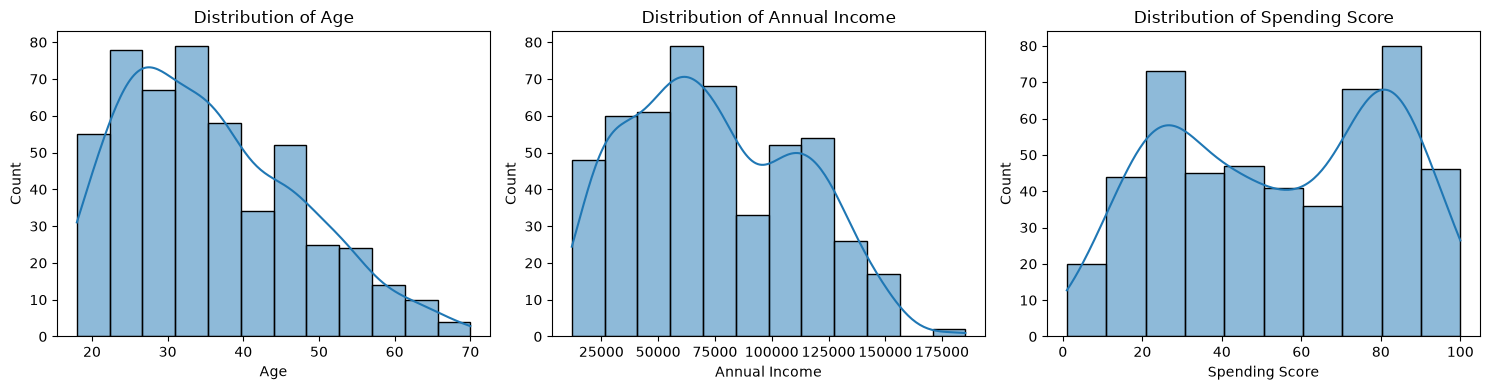

In [6]:

features = ["Age", "Annual Income", "Spending Score"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for column, axis in zip(features, axes):
    sns.histplot(data=customers, x=column, kde=True, ax=axis)
    axis.set_title(f"Distribution of {column}")

plt.tight_layout()
plt.show()


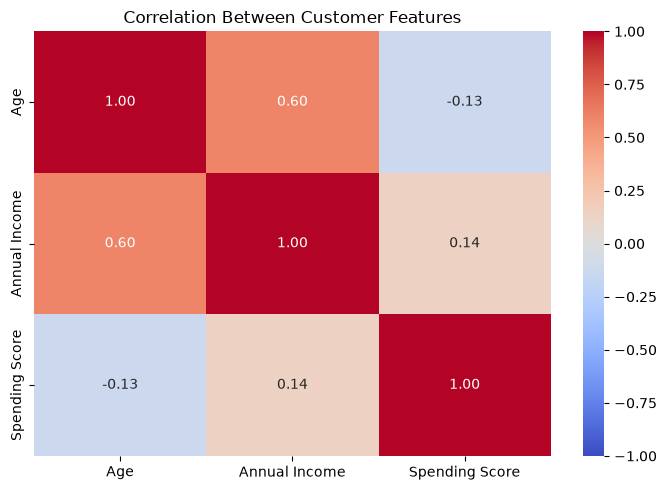

In [7]:

plt.figure(figsize=(7, 5))

sns.heatmap(
    customers[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Customer Features")
plt.tight_layout()
plt.show()


In [8]:

customer_features = customers[
    ["Age", "Annual Income", "Spending Score"]
].copy()

print("Features selected for clustering:")
display(customer_features.head())

print("\nFeature dimensions:", customer_features.shape)


Features selected for clustering:


,Age,Annual Income,Spending Score
0,23,87726,92
1,26,18860,28
2,41,61435,100
3,38,111119,74
4,33,121280,81



Feature dimensions: (500, 3)


In [9]:

scaler = RobustScaler()

scaled_features = scaler.fit_transform(customer_features)

scaled_customers = pd.DataFrame(
    scaled_features,
    columns=customer_features.columns
)

print("Scaling completed successfully!")
display(scaled_customers.head())


Scaling completed successfully!


,Age,Annual Income,Spending Score
0,-0.611111,0.271532,0.679245
1,-0.444444,-0.863274,-0.528302
2,0.388889,-0.161703,0.830189
3,0.222222,0.657013,0.339623
4,-0.055556,0.824451,0.471698


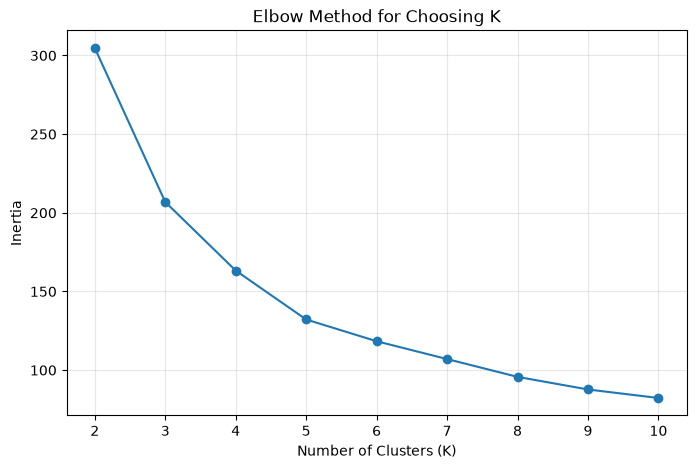

In [10]:

cluster_range = range(2, 11)
inertia_values = []

for k in cluster_range:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    model.fit(scaled_customers)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(
    list(cluster_range),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing K")
plt.xticks(list(cluster_range))
plt.grid(True, alpha=0.3)
plt.show()


,Number of Clusters,Silhouette Score
0,2,0.385
1,3,0.365
2,4,0.349
3,5,0.365
4,6,0.349
5,7,0.332
6,8,0.319
7,9,0.308
8,10,0.306


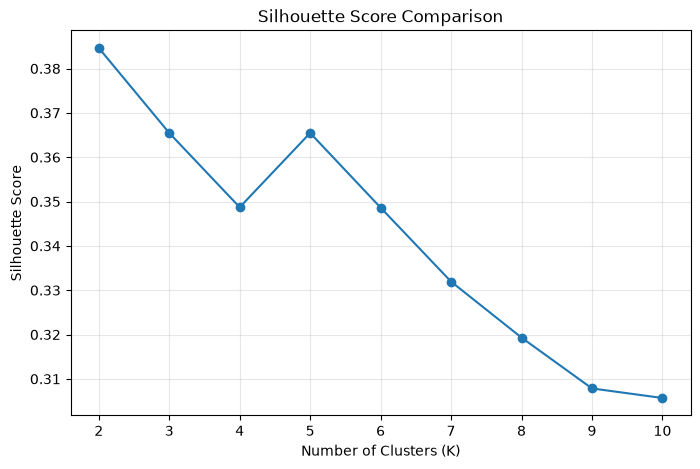

In [11]:

silhouette_values = []

for k in cluster_range:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = model.fit_predict(scaled_customers)
    score = silhouette_score(scaled_customers, labels)
    silhouette_values.append(score)

score_table = pd.DataFrame({
    "Number of Clusters": list(cluster_range),
    "Silhouette Score": silhouette_values
})

display(score_table.round(3))

plt.figure(figsize=(8, 5))
plt.plot(
    list(cluster_range),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison")
plt.xticks(list(cluster_range))
plt.grid(True, alpha=0.3)
plt.show()


In [12]:

final_k = 5

kmeans_model = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

customers["Cluster"] = kmeans_model.fit_predict(scaled_customers)

print("K-Means model trained successfully!")
print("Number of clusters:", final_k)

print("\nCustomers assigned to each cluster:")
display(
    customers["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Number of Customers")
)


K-Means model trained successfully!
Number of clusters: 5

Customers assigned to each cluster:


,Number of Customers
Cluster,
0,86
1,98
2,96
3,106
4,114


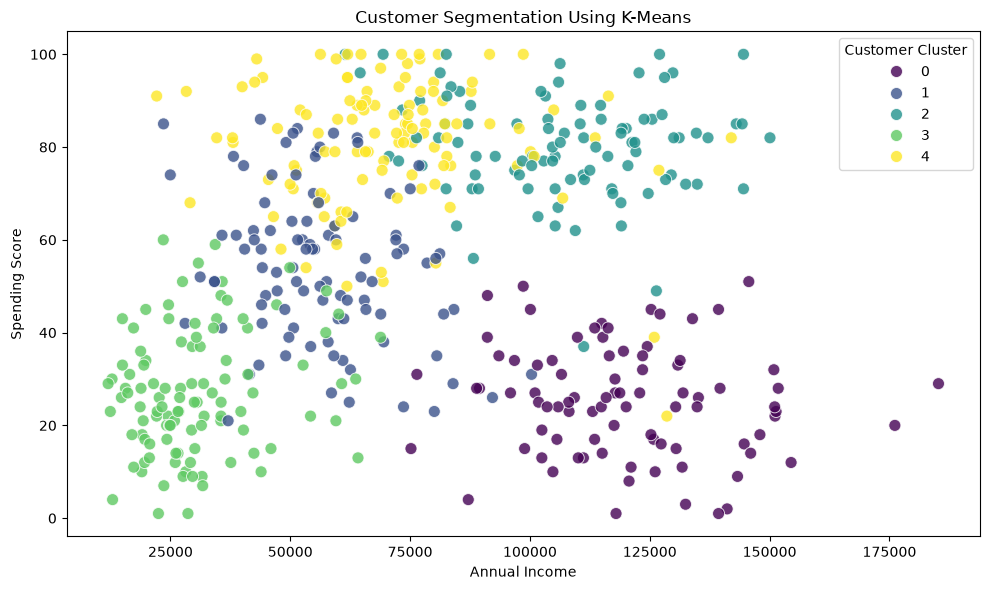

In [13]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customers,
    x="Annual Income",
    y="Spending Score",
    hue="Cluster",
    palette="viridis",
    s=75,
    alpha=0.8
)

plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.legend(title="Customer Cluster")
plt.tight_layout()
plt.show()


In [14]:

cluster_summary = customers.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income", "mean"),
    Average_Spending_Score=("Spending Score", "mean")
).round(2)

display(cluster_summary)


,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,86,52.19,120163.05,25.30
1,98,37.60,56319.92,54.41
2,96,41.80,106686.05,80.18
3,106,25.18,30477.07,27.01
4,114,25.72,70625.84,81.02


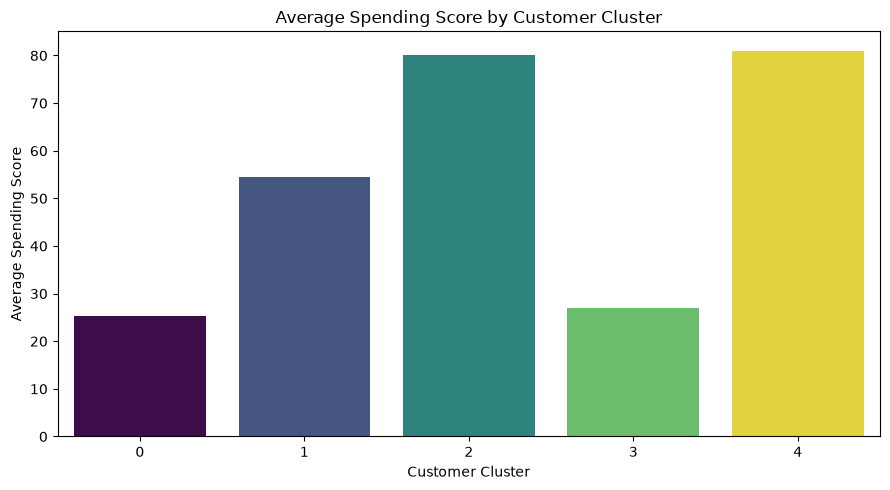

In [15]:

plt.figure(figsize=(9, 5))

sns.barplot(
    x=cluster_summary.index,
    y=cluster_summary["Average_Spending_Score"],
    hue=cluster_summary.index,
    palette="viridis",
    legend=False
)

plt.title("Average Spending Score by Customer Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Spending Score")
plt.tight_layout()
plt.show()


In [16]:

final_silhouette = silhouette_score(
    scaled_customers,
    customers["Cluster"]
)

print("Final number of clusters:", final_k)
print("Final silhouette score:", round(final_silhouette, 3))


Final number of clusters: 5
Final silhouette score: 0.365


In [17]:

output_file = "segmented_customers.csv"

customers.to_csv(output_file, index=False)

print("Segmented customer data saved successfully!")
print("File name:", output_file)


Segmented customer data saved successfully!
File name: segmented_customers.csv


In [18]:

cluster_summary.to_csv("customer_cluster_summary.csv")

print("Cluster summary saved successfully!")


Cluster summary saved successfully!
